# LSTM Portfolio Analysis

This notebook performs the complete supervised-learning stage: data preparation, exploratory analysis, leakage-safe splitting, LSTM training, prediction, portfolio construction, baseline comparison, and saving results for the DRL notebook.

## 1. Setup and reproducibility

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from src.data.download_data import download_data
from src.data.preprocess import preprocess_data
from src.data.splits import chronological_split
from src.portfolio.baselines import equal_weight_weights, fixed_weight_backtest, markowitz_weights
from src.portfolio.metrics import performance_summary
from src.utils.config import DEFAULT_CONFIG

SEED = DEFAULT_CONFIG.seed
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Project root: {PROJECT_ROOT}")
print(f"Device: {DEVICE}")

Project root: d:\Codings\DRL\Portfolio_DRL
Device: cuda


## 2. Load data once

The processed return file is loaded once into `returns`. If it does not exist, the notebook downloads and preprocesses the prices first.

In [2]:
returns_path = PROJECT_ROOT / DEFAULT_CONFIG.returns_path
if not returns_path.exists():
    download_data()
    preprocess_data()

returns = pd.read_csv(returns_path, index_col=0, parse_dates=True).dropna().sort_index()
prices = (1 + returns).cumprod()
print(f"Observations: {len(returns):,}")
print(f"Assets: {list(returns.columns)}")
print(f"Period: {returns.index.min().date()} to {returns.index.max().date()}")
returns.head()

Data downloaded successfully.
Ticker        AAPL    AMZN   GOOGL     META    MSFT
Date                                               
2018-01-02 40.2671 59.4505 53.1889 179.8407 78.6999
2018-01-03 40.2601 60.2100 54.0963 183.0624 79.0662
2018-01-04 40.4471 60.4795 54.3064 182.7254 79.7621
2018-01-05 40.9076 61.4570 55.0266 185.2234 80.7510
2018-01-08 40.7556 62.3435 55.2208 186.6410 80.8334
Preprocessing complete.
              AAPL   AMZN   GOOGL    META    MSFT
Date                                             
2018-01-03 -0.0002 0.0128  0.0171  0.0179  0.0047
2018-01-04  0.0046 0.0045  0.0039 -0.0018  0.0088
2018-01-05  0.0114 0.0162  0.0133  0.0137  0.0124
2018-01-08 -0.0037 0.0144  0.0035  0.0077  0.0010
2018-01-09 -0.0001 0.0047 -0.0013 -0.0022 -0.0007
Observations: 2,010
Assets: ['AAPL', 'AMZN', 'GOOGL', 'META', 'MSFT']
Period: 2018-01-03 to 2025-12-31


,AAPL,AMZN,GOOGL,META,MSFT
Date,,,,,
2018-01-03,-0.0002,0.0128,0.0171,0.0179,0.0047
2018-01-04,0.0046,0.0045,0.0039,-0.0018,0.0088
2018-01-05,0.0114,0.0162,0.0133,0.0137,0.0124
2018-01-08,-0.0037,0.0144,0.0035,0.0077,0.0010
2018-01-09,-0.0001,0.0047,-0.0013,-0.0022,-0.0007


## 3. Data exploration

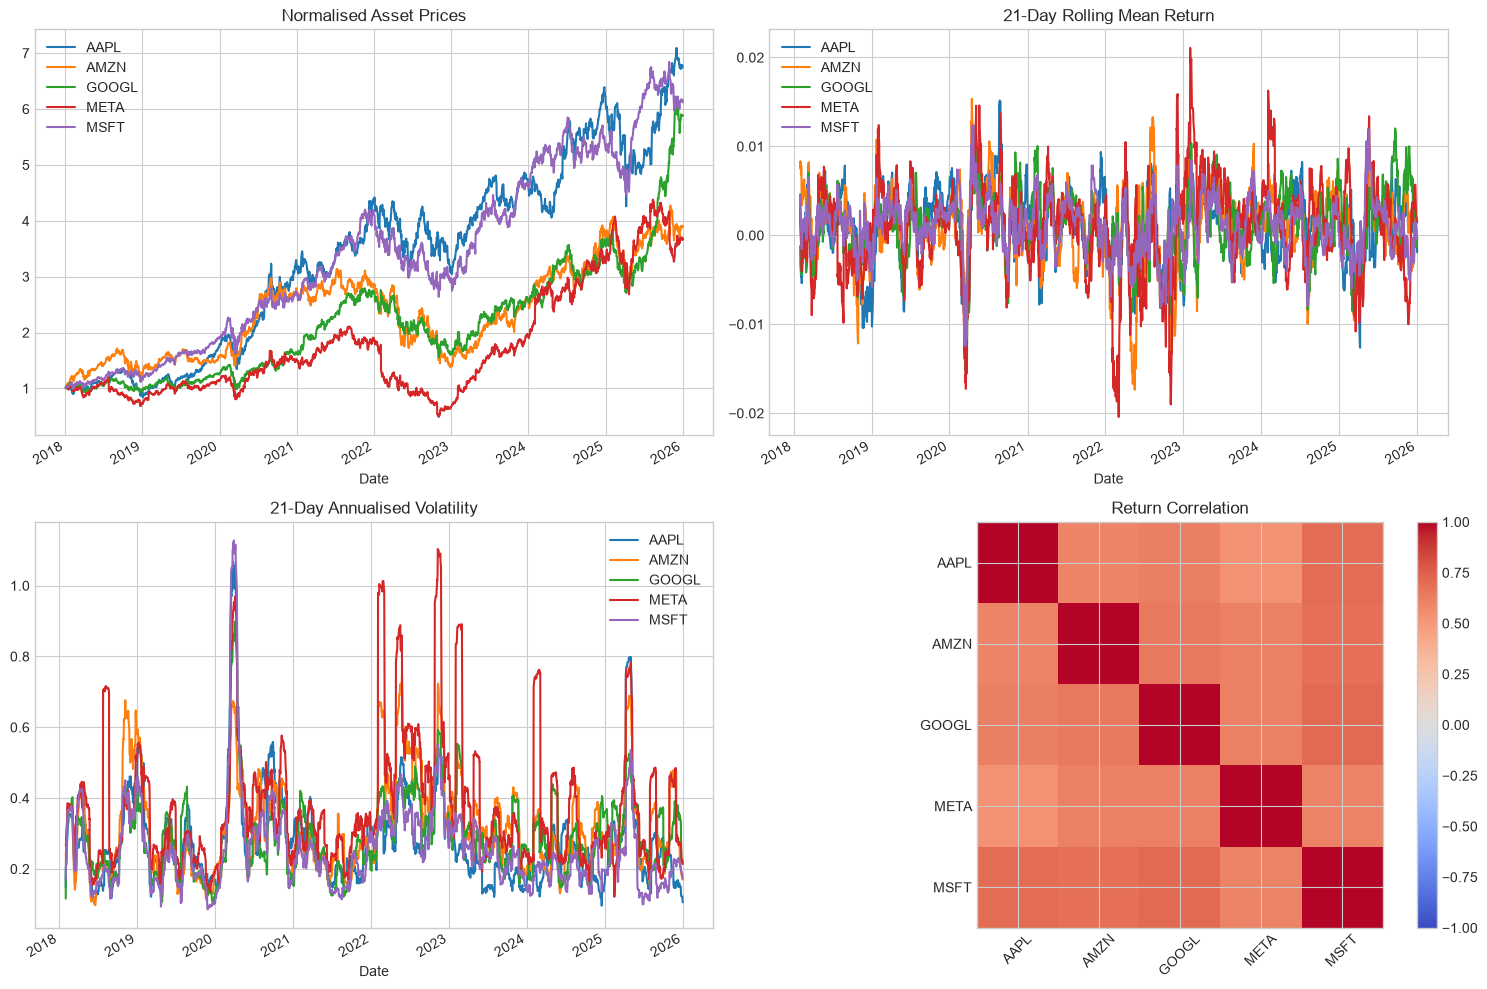

,count,mean,std,min,25%,50%,75%,max
AAPL,"2,010.0000",0.0011,0.0194,-0.1286,-0.0079,0.0012,0.0111,0.1533
AMZN,"2,010.0000",0.0009,0.0217,-0.1405,-0.0102,0.0011,0.0123,0.1354
GOOGL,"2,010.0000",0.0011,0.0195,-0.1163,-0.0085,0.0014,0.0113,0.1022
META,"2,010.0000",0.0010,0.0261,-0.2639,-0.0110,0.0010,0.0134,0.2328
MSFT,"2,010.0000",0.0011,0.0179,-0.1474,-0.0074,0.0013,0.0103,0.1422


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
prices.plot(ax=axes[0, 0], title="Normalised Asset Prices")
returns.rolling(21).mean().plot(ax=axes[0, 1], title="21-Day Rolling Mean Return")
returns.rolling(21).std().mul(np.sqrt(252)).plot(ax=axes[1, 0], title="21-Day Annualised Volatility")
correlation = returns.corr()
image = axes[1, 1].imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
axes[1, 1].set_title("Return Correlation")
axes[1, 1].set_xticks(range(len(correlation)), correlation.columns, rotation=45)
axes[1, 1].set_yticks(range(len(correlation)), correlation.index)
fig.colorbar(image, ax=axes[1, 1], fraction=0.046)
plt.tight_layout()
plt.show()

returns.describe().T

## 4. Chronological train, validation, and test split

Scaling parameters are fitted on training data only. The LSTM predicts the next-day return of every asset from the previous 30 trading days.

In [4]:
train_returns, validation_returns, test_returns = chronological_split(
    returns,
    DEFAULT_CONFIG.train_end,
    DEFAULT_CONFIG.validation_end,
)
print({"train": len(train_returns), "validation": len(validation_returns), "test": len(test_returns)})

scaler = StandardScaler().fit(train_returns)
scaled_all = pd.DataFrame(
    scaler.transform(returns),
    index=returns.index,
    columns=returns.columns,
)

LOOKBACK = DEFAULT_CONFIG.lookback_window

def make_sequences(frame, target_dates):
    x_values, y_values, dates = [], [], []
    target_set = set(target_dates)
    for index in range(LOOKBACK, len(frame)):
        date = frame.index[index]
        if date in target_set:
            x_values.append(frame.iloc[index - LOOKBACK:index].to_numpy())
            y_values.append(frame.iloc[index].to_numpy())
            dates.append(date)
    return (
        torch.tensor(np.asarray(x_values), dtype=torch.float32),
        torch.tensor(np.asarray(y_values), dtype=torch.float32),
        pd.DatetimeIndex(dates),
    )

x_train, y_train, train_dates = make_sequences(scaled_all, train_returns.index)
x_validation, y_validation, validation_dates = make_sequences(scaled_all, validation_returns.index)
x_test, y_test, test_dates = make_sequences(scaled_all, test_returns.index)
print(x_train.shape, x_validation.shape, x_test.shape)

{'train': 1258, 'validation': 250, 'test': 502}
torch.Size([1228, 30, 5]) torch.Size([250, 30, 5]) torch.Size([502, 30, 5])


## 5. Define and train the multi-asset LSTM

Epoch 001 | train=1.008717 | validation=0.725725
Epoch 010 | train=0.947696 | validation=0.728601
Early stopping at epoch 13


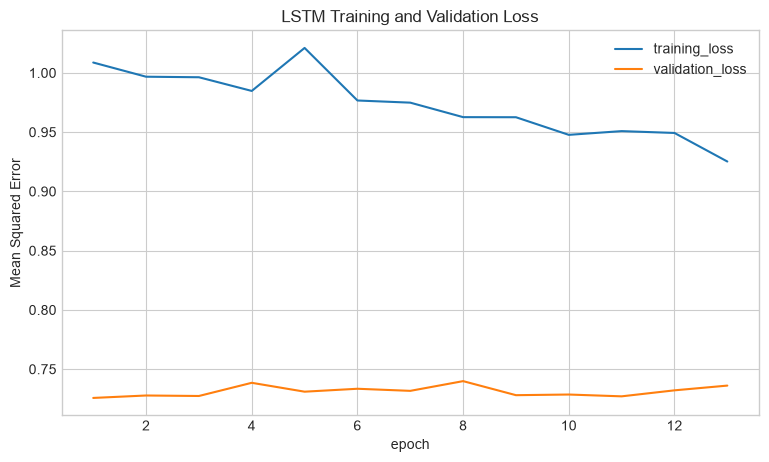

In [5]:
class MultiAssetLSTM(nn.Module):
    def __init__(self, number_of_assets, hidden_size=64, layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=number_of_assets,
            hidden_size=hidden_size,
            num_layers=layers,
            dropout=dropout if layers > 1 else 0.0,
            batch_first=True,
        )
        self.output = nn.Linear(hidden_size, number_of_assets)

    def forward(self, values):
        sequence, _ = self.lstm(values)
        return self.output(sequence[:, -1, :])

BATCH_SIZE = 32
MAX_EPOCHS = 100
PATIENCE = 12
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(TensorDataset(x_validation, y_validation), batch_size=BATCH_SIZE)

model = MultiAssetLSTM(returns.shape[1]).to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
history = []
best_validation_loss = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    training_losses = []
    for features, targets in train_loader:
        features, targets = features.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(features), targets)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        training_losses.append(loss.item())

    model.eval()
    validation_losses = []
    with torch.no_grad():
        for features, targets in validation_loader:
            features, targets = features.to(DEVICE), targets.to(DEVICE)
            validation_losses.append(criterion(model(features), targets).item())

    training_loss = float(np.mean(training_losses))
    validation_loss = float(np.mean(validation_losses))
    history.append({"epoch": epoch, "training_loss": training_loss, "validation_loss": validation_loss})

    if validation_loss < best_validation_loss - 1e-5:
        best_validation_loss = validation_loss
        best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:03d} | train={training_loss:.6f} | validation={validation_loss:.6f}")
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
history = pd.DataFrame(history).set_index("epoch")
history.plot(figsize=(9, 5), title="LSTM Training and Validation Loss")
plt.ylabel("Mean Squared Error")
plt.show()

## 6. Test predictions and prediction-quality charts

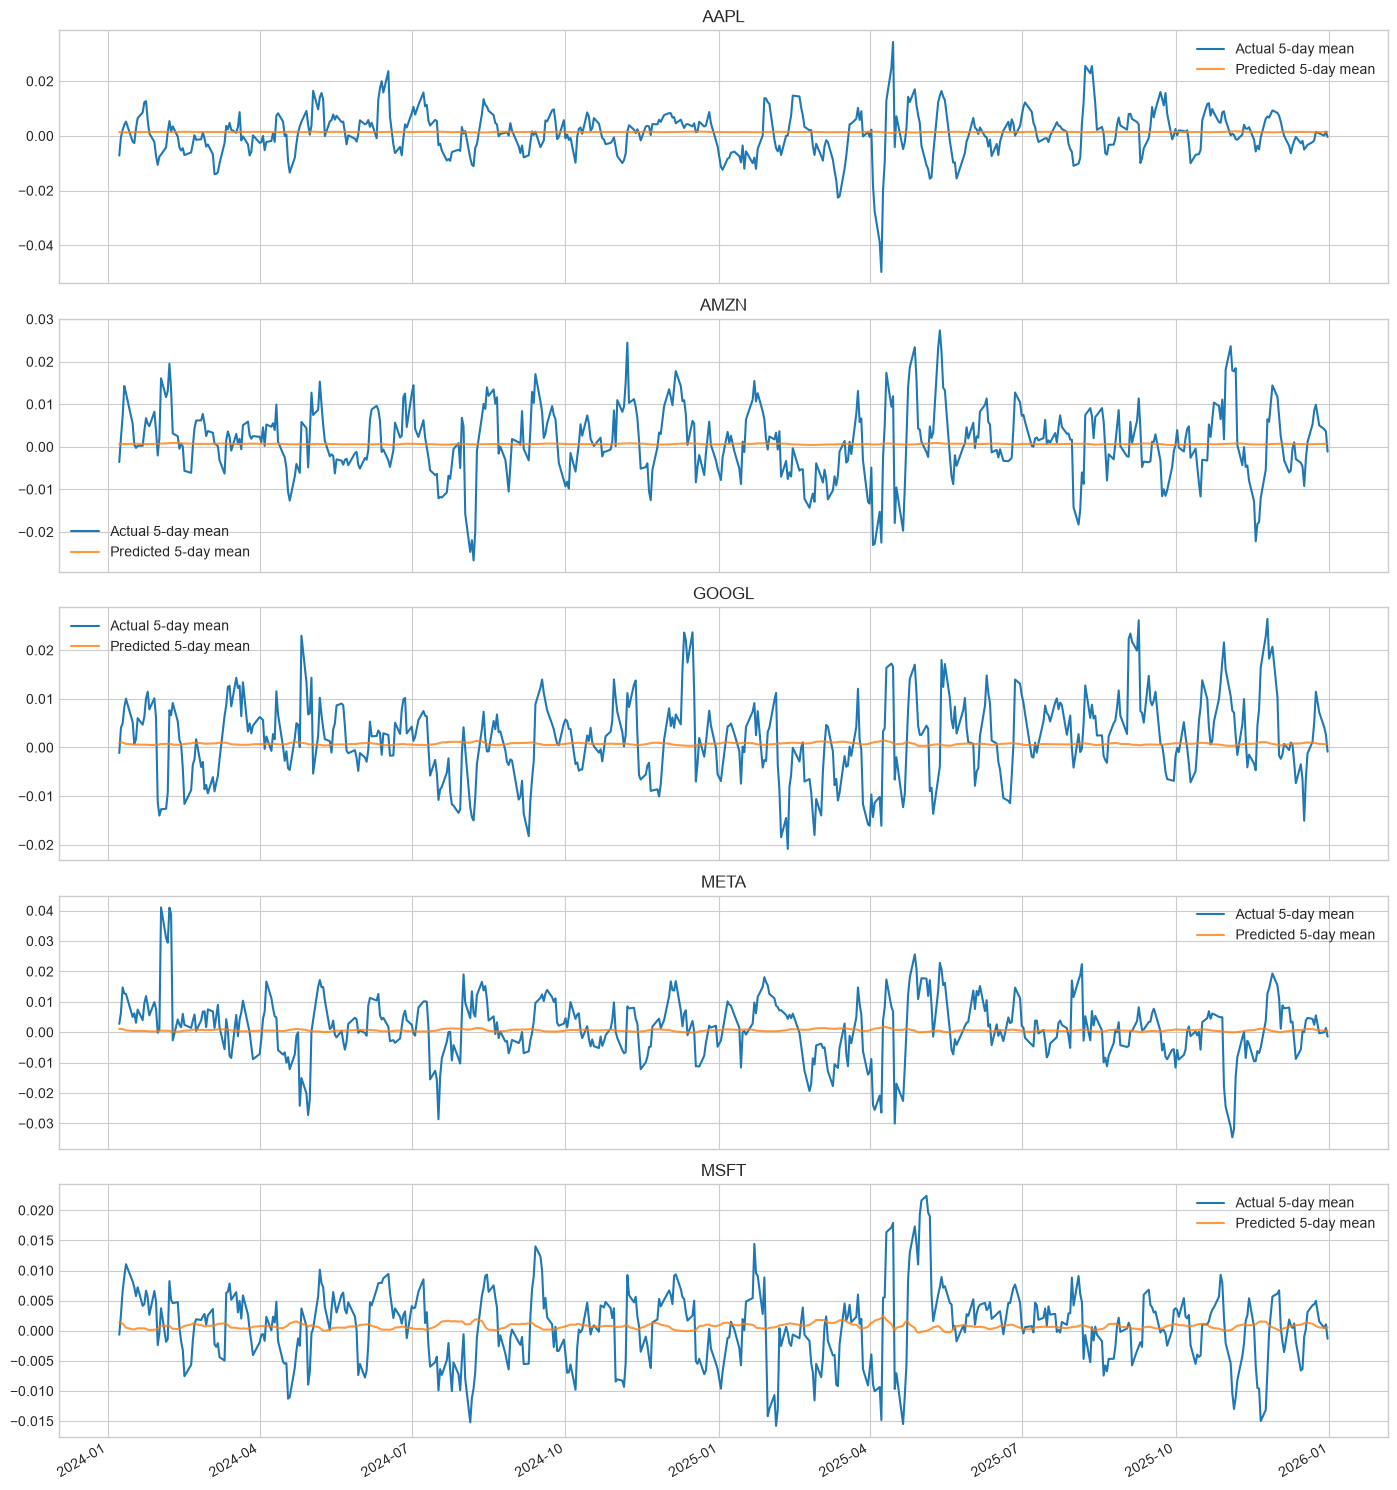

,directional_accuracy,prediction_correlation
AAPL,0.5438,-0.0361
AMZN,0.5279,0.0487
GOOGL,0.5657,0.0424
META,0.5299,0.1023
MSFT,0.5239,0.0673


In [6]:
model.eval()
with torch.no_grad():
    scaled_predictions = model(x_test.to(DEVICE)).cpu().numpy()

predictions = pd.DataFrame(
    scaler.inverse_transform(scaled_predictions),
    index=test_dates,
    columns=returns.columns,
)
actual = test_returns.loc[test_dates]

fig, axes = plt.subplots(len(returns.columns), 1, figsize=(14, 3 * len(returns.columns)), sharex=True)
for asset, axis in zip(returns.columns, np.atleast_1d(axes)):
    actual[asset].rolling(5).mean().plot(ax=axis, label="Actual 5-day mean")
    predictions[asset].rolling(5).mean().plot(ax=axis, label="Predicted 5-day mean", alpha=0.8)
    axis.set_title(asset)
    axis.legend()
plt.tight_layout()
plt.show()

directional_accuracy = (np.sign(predictions) == np.sign(actual)).mean().rename("directional_accuracy")
prediction_correlation = predictions.corrwith(actual).rename("prediction_correlation")
pd.concat([directional_accuracy, prediction_correlation], axis=1)

## 7. Convert predictions into portfolio weights

Positive forecasts are normalised into long-only weights. If all forecasts are non-positive, the portfolio uses equal weights. Turnover costs are deducted daily.

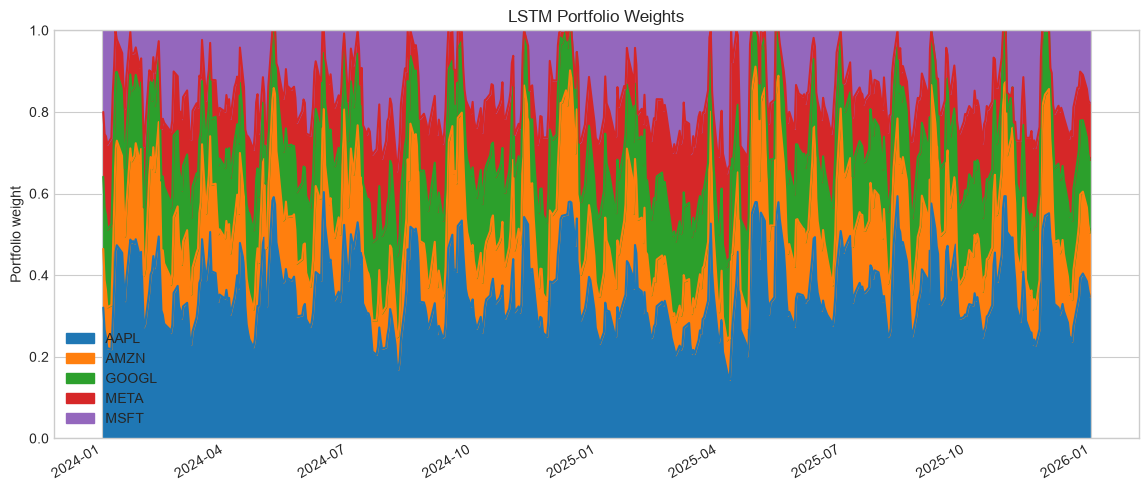

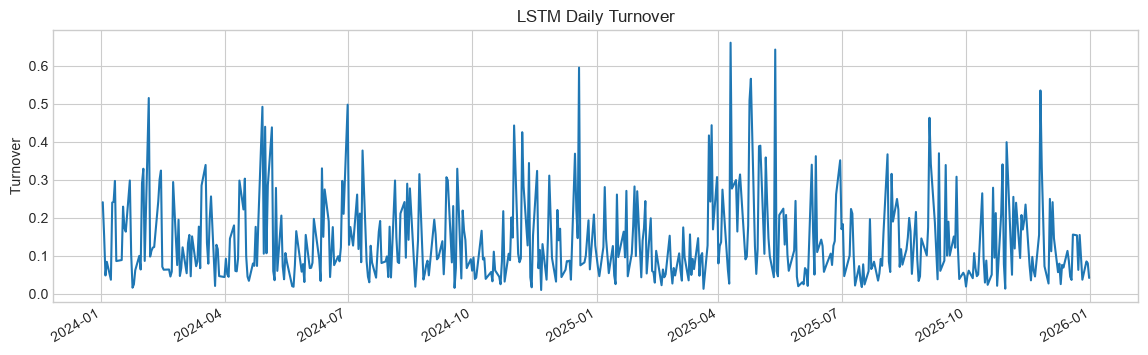

In [7]:
positive_predictions = predictions.clip(lower=0)
weights = positive_predictions.div(positive_predictions.sum(axis=1).replace(0, np.nan), axis=0)
weights = weights.fillna(1 / returns.shape[1])

previous_weights = pd.DataFrame(
    np.vstack([np.full(returns.shape[1], 1 / returns.shape[1]), weights.iloc[:-1].to_numpy()]),
    index=weights.index,
    columns=weights.columns,
)
turnover = weights.sub(previous_weights).abs().sum(axis=1)
lstm_returns = (weights * actual).sum(axis=1) - DEFAULT_CONFIG.transaction_cost * turnover
lstm_returns.name = "LSTM"

weights.plot.area(figsize=(14, 6), title="LSTM Portfolio Weights", ylim=(0, 1))
plt.ylabel("Portfolio weight")
plt.show()

turnover.plot(figsize=(14, 4), title="LSTM Daily Turnover")
plt.ylabel("Turnover")
plt.show()

## 8. LSTM versus classical baselines

,total_return,annualised_return,annualised_volatility,sharpe_ratio,sortino_ratio,maximum_drawdown
LSTM,0.5774,0.2571,0.2267,1.1221,1.1206,0.2388
Equal Weight,0.6972,0.3041,0.2326,1.2576,1.2971,0.2529
Markowitz,0.4044,0.1859,0.2089,0.9199,0.9145,0.2563


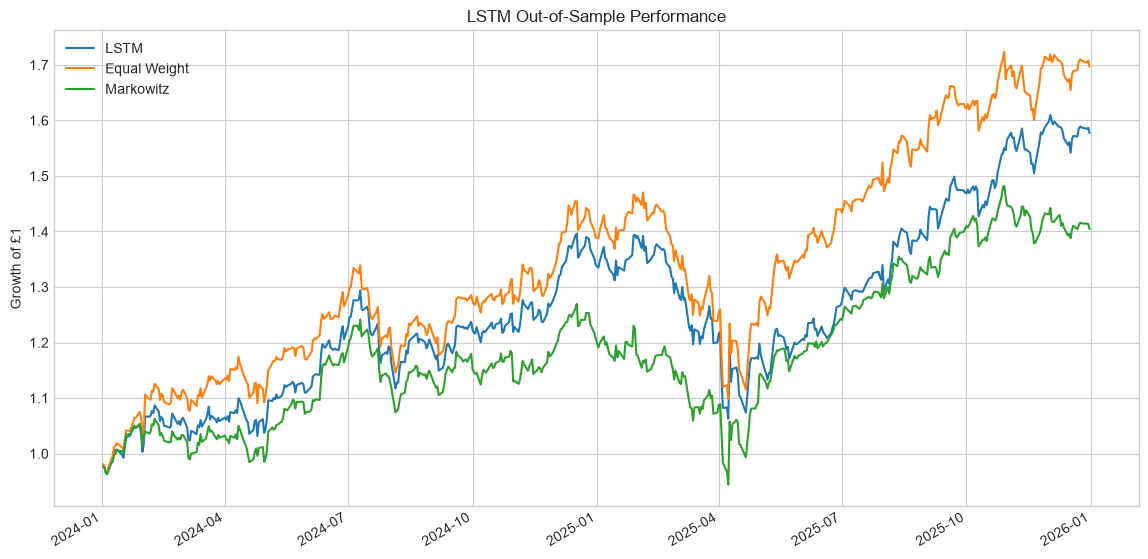

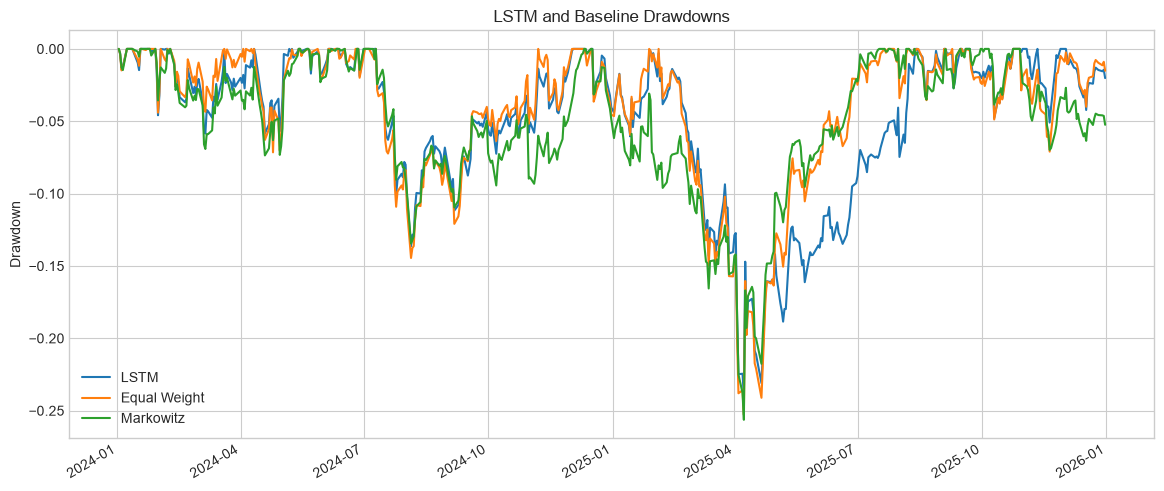

In [8]:
equal_weight = fixed_weight_backtest(
    actual,
    equal_weight_weights(actual.shape[1]),
    DEFAULT_CONFIG.transaction_cost,
).rename("Equal Weight")
markowitz = fixed_weight_backtest(
    actual,
    markowitz_weights(train_returns),
    DEFAULT_CONFIG.transaction_cost,
).rename("Markowitz")

lstm_comparison = pd.concat([lstm_returns, equal_weight, markowitz], axis=1).dropna()
lstm_metrics = pd.DataFrame({name: performance_summary(series) for name, series in lstm_comparison.items()}).T
display(lstm_metrics.style.format("{:.4f}"))

(1 + lstm_comparison).cumprod().plot(figsize=(14, 7), title="LSTM Out-of-Sample Performance")
plt.ylabel("Growth of £1")
plt.show()

wealth = (1 + lstm_comparison).cumprod()
drawdown = wealth.div(wealth.cummax()).sub(1)
drawdown.plot(figsize=(14, 6), title="LSTM and Baseline Drawdowns")
plt.ylabel("Drawdown")
plt.show()

## 9. Save model and results for the DQN/PPO notebook

In [9]:
model_directory = PROJECT_ROOT / "results/models"
report_directory = PROJECT_ROOT / "results/reports"
figure_directory = PROJECT_ROOT / "results/figures"
for directory in (model_directory, report_directory, figure_directory):
    directory.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state": model.state_dict(),
        "assets": list(returns.columns),
        "lookback": LOOKBACK,
        "scaler_mean": scaler.mean_,
        "scaler_scale": scaler.scale_,
    },
    model_directory / "lstm_portfolio.pth",
)
history.to_csv(report_directory / "lstm_training_history.csv")
predictions.to_csv(report_directory / "lstm_predictions.csv")
weights.to_csv(report_directory / "lstm_weights.csv")
lstm_comparison.to_csv(report_directory / "lstm_out_of_sample_returns.csv")
lstm_metrics.to_csv(report_directory / "lstm_performance_metrics.csv")

print("Saved LSTM model and results. The DRL notebook will load these files directly.")

Saved LSTM model and results. The DRL notebook will load these files directly.
